# 04 – Stichtagsvergleich nach dem Datenbruch
## 1. Ziel und unveränderte Kohorte
Verglichen werden der bisherige Stichtag (letztes gültiges Session-Ende) und der
16.07.2023, Tagesende UTC. Die gleichen 5.998 Nutzer bleiben enthalten; die Kohorte
wird ausdrücklich **nicht neu ausgewählt**. Das untersucht die Empfindlichkeit der bestehenden
Analyse, keine vollständig historisch rekonstruierte Kohorte: Die Auswahl selbst nutzt weiterhin
das ursprüngliche Beobachtungsfenster.

Es werden die Rechenformeln aus der eingefrorenen Baseline `src/02_Features_Baseline.ipynb` wiederverwendet,
jedoch weder dessen SQL-Abfragen noch dessen Exporte ausgeführt. Eingabedateien und
Quellnotebook werden anhand von SHA-256 geprüft und bleiben unverändert.
Pakete und Konfiguration entsprechen dem Setup von Notebook 02.

In [1]:
from pathlib import Path
from types import SimpleNamespace
from itertools import permutations
import ast
import json
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from airports import airport_data
from IPython.display import HTML, display
from html import escape
import config
import eda_functions as eda

THEME=config.THEME
PERK_COLORS=config.PERK_COLORS
WIDTH=config.WIDTH
CUTOFF=pd.Timestamp(config.ANALYSIS_REFERENCE_DATE)
SOURCE_NOTEBOOK=config.BASELINE_FEATURE_NOTEBOOK
source_bytes=SOURCE_NOTEBOOK.read_bytes()
source_notebook=json.loads(source_bytes.decode("utf8"))
input_folder=config.DATA_PREPROCESSING_FOLDER
input_hashes={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in input_folder.glob("*.csv")}
source_hash=hashlib.sha256(source_bytes).hexdigest()

def source_cell(prefix):
    matches=["".join(c["source"]) for c in source_notebook["cells"] if c["cell_type"]=="code" and "".join(c["source"]).startswith(prefix)]
    if len(matches)!=1:raise ValueError(f"Feature-Pipeline nicht eindeutig gefunden: {prefix}")
    return matches[0]

def draw_table(frame,title):
    eda.display_table(frame,title=title,card_width=WIDTH,max_height=450)

def run_scenario(cutoff=None):
    # Bestehende Formeln wiederverwenden; keine SQL-, Installations- oder Exportzellen ausführen.
    silent_eda=SimpleNamespace(display_table=lambda *a,**k:None,display_tables=lambda *a,**k:None,preview_tables=lambda *a,**k:None)
    scope=dict(pd=pd,np=np,plt=plt,sns=sns,KMeans=KMeans,silhouette_score=silhouette_score,
        adjusted_rand_score=adjusted_rand_score,StandardScaler=StandardScaler,SimpleImputer=SimpleImputer,
        PCA=PCA,airport_data=airport_data,HTML=HTML,escape=escape,display=lambda *a,**k:None,
        config=config,eda=silent_eda,THEME=THEME,PERK_COLORS=PERK_COLORS,WIDTH=WIDTH,
        DATA_PREPROCESSING_FOLDER=input_folder,REFERENCE_OVERRIDE=cutoff)
    setup_tree=ast.parse("".join(source_notebook["cells"][1]["source"]))
    for node in setup_tree.body:
        if isinstance(node,ast.FunctionDef):exec(compile(ast.Module(body=[node],type_ignores=[]),"feature_helpers","exec"),scope)
    scope["THEME_DIVERGING_CMAP"]=scope["apply_config_plot_theme"]()
    # Diagramme dieses Rechenlaufs werden geschlossen; Vergleichsdiagramme folgen separat.
    original_show=plt.show
    plt.show=lambda:plt.close("all")
    prefixes=["files = {","quality_records=","activity=","trip_sessions=","flight_components=",
              "destinations=","route_rows =","storno=",'for kind in ["flight","hotel"]:',"for column in count_columns:","candidate_reasons ="]
    try:
        for prefix in prefixes:
            text=source_cell(prefix)
            if prefix=="quality_records=":
                anchor='reference_date=sessions_analysis["session_end"].max()'
                assert text.count(anchor)==1
                text=text.replace(anchor,anchor+"\n"+"""if REFERENCE_OVERRIDE is not None:
    reference_date=REFERENCE_OVERRIDE
    birth=users_analysis["birthdate"]
    pending=birth.dt.month.gt(reference_date.month) | (birth.dt.month.eq(reference_date.month) & birth.dt.day.gt(reference_date.day))
    users_analysis["age_years"]=(reference_date.year-birth.dt.year-pending.astype(int)).where(birth.le(reference_date))
    signup=users_analysis["sign_up_date"]
    users_analysis["customer_tenure_days"]=(reference_date.normalize()-signup.dt.normalize()).dt.days.where(signup.le(reference_date))
    users_analysis["age_group"]=pd.cut(users_analysis["age_years"],bins=[0,18,21,25,35,45,55,65,np.inf],labels=["Unter 18","18-20","21-24","25-34","35-44","45-54","55-64","65+"],right=False)
""")
            exec(compile(text,"feature_step","exec"),scope)
        rule_source=source_cell("def make_rule_segments(")
        for node in ast.parse(rule_source).body:
            if isinstance(node,ast.FunctionDef):exec(compile(ast.Module(body=[node],type_ignores=[]),"rule_functions","exec"),scope)
        scope["rule_segments"],scope["rule_flags"]=scope["make_rule_segments"]()
        exec(compile(source_cell("def wilson_lower("),"perk_rules","exec"),scope)
        # Gleiche Arbeits-Clusterzahl k=3 in beiden Szenarien; kein Wechsel von k als Störfaktor.
        km=KMeans(n_clusters=3,n_init=20,random_state=42).fit(scope["cluster_matrix"])
        scope["cluster_labels"]=pd.Series(km.labels_,index=scope["user_features"].index,name="cluster")
        scope["preferred_k"]=3;scope["k_models"]={3:km}
        exec(compile(source_cell("ranked_candidates="),"decisions","exec"),scope)
    finally:plt.show=original_show
    return scope

## 2. Features und Cluster neu berechnen
Alter, Altersgruppe und Kundendauer werden auf den jeweiligen Stichtag bezogen. Alle
Ereignisfeatures verwenden nur Sessions bis einschließlich des Stichtags. Zukünftige
Reisebeginne einer bereits gebuchten Reise bleiben geplante Merkmale, keine angetretenen Reisen.
Preis- und Stammdaten sind nicht historisch versioniert; dieser Vergleich kann deren
Verfügbarkeit am früheren Stichtag nicht beweisen.

Zwei Clustervergleiche werden getrennt: festes Baseline-Modell einschließlich Vorverarbeitung
und vollständiger Neufit bei konstantem k=3. Beim Neufit werden Cluster-Nummern für eine
Wechseltabelle optimal angeglichen; ARI ist ohnehin nummerierungsunabhängig.

In [3]:
baseline=run_scenario()
earlier=run_scenario(CUTOFF)
before=baseline["user_features"].sort_index()
after=earlier["user_features"].sort_index()
assert before.index.equals(after.index) and len(before)==5998
assert earlier["fs"]["session_start"].le(CUTOFF).all()

feature_rows=[]
for col in before:
    a,b=before[col],after[col]
    changed=~(a.eq(b).fillna(False)|(a.isna()&b.isna()))
    item={"Feature":col,"Geänderte Nutzer":int(changed.sum()),"Geändert (%)":changed.mean()*100,
          "Fehlend vorher":int(a.isna().sum()),"Fehlend früher":int(b.isna().sum())}
    if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
        aa=pd.to_numeric(a,errors="coerce").astype(float);bb=pd.to_numeric(b,errors="coerce").astype(float)
        item.update({"Mittel vorher":aa.mean(),"Mittel früher":bb.mean(),"Median absolute Änderung":(bb-aa).abs().median(),"Max absolute Änderung":(bb-aa).abs().max()})
    feature_rows.append(item)
feature_changes=pd.DataFrame(feature_rows).sort_values("Geänderte Nutzer",ascending=False)
draw_table(feature_changes.round(3),"Feature-Änderungen bei identischer Nutzerkohorte")

# Feste Baseline-Vorverarbeitung: Effekte veränderter Eingaben von neuem Fit unterscheiden.
columns=baseline["retained"]
raw=baseline["model_raw"][columns].copy()
lower=raw.quantile(.01);upper=raw.quantile(.99)
clipped=raw.clip(lower,upper,axis=1)
fixed_imputer=SimpleImputer(strategy="median").fit(clipped)
fixed_scaler=StandardScaler().fit(fixed_imputer.transform(clipped))
def frozen_matrix(features):
    x=features[columns].apply(pd.to_numeric,errors="coerce").astype(float).copy()
    if "booked_trip_count" in x:x["booked_trip_count"]=np.log1p(x["booked_trip_count"])
    x=x.clip(lower,upper,axis=1)
    matrix=pd.DataFrame(fixed_scaler.transform(fixed_imputer.transform(x)),index=x.index,columns=columns)
    matrix["no_flight_history"]=features["booked_flight_count"].eq(0).astype(float)
    matrix["no_hotel_history"]=features["booked_hotel_count"].eq(0).astype(float)
    return matrix
assert np.allclose(frozen_matrix(before),baseline["cluster_matrix"])
fixed_labels=pd.Series(baseline["k_models"][3].predict(frozen_matrix(after)),index=after.index)
old_labels=baseline["cluster_labels"]
refit_labels=earlier["cluster_labels"]
# Neufit-Nummern optimal angleichen; ARI ist ohnehin unabhängig von Cluster-Nummern.
best=max(permutations(range(3)),key=lambda perm:sum(refit_labels.map(dict(enumerate(perm))).eq(old_labels)))
aligned_refit=refit_labels.map(dict(enumerate(best)))
cluster_comparison=pd.DataFrame([
    {"Vergleich":"Baseline-Modell und Skalierung fest","ARI":adjusted_rand_score(old_labels,fixed_labels),"Geänderte Nutzer":int(old_labels.ne(fixed_labels).sum())},
    {"Vergleich":"Vorverarbeitung und k=3 neu angepasst","ARI":adjusted_rand_score(old_labels,refit_labels),"Geänderte Nutzer":int(old_labels.ne(aligned_refit).sum())},
])
draw_table(cluster_comparison.round(4),"Einfluss des Stichtags auf k=3")
draw_table(pd.crosstab(old_labels.rename("Vorher"),fixed_labels.rename("Früher, festes Modell")),"Clusterwechsel bei festem Modell")
k_rows=[]
for scenario,name in [(baseline,"Bisher"),(earlier,"16.07.2023")]:
    for k in range(2,6):
        km=KMeans(n_clusters=k,n_init=20,random_state=42).fit(scenario["cluster_matrix"])
        sizes=pd.Series(km.labels_).value_counts()
        k_rows.append({"Szenario":name,"k":k,"Silhouette":silhouette_score(scenario["cluster_matrix"],km.labels_,sample_size=2000,random_state=42),"Größte Gruppe (%)":sizes.max()/len(before)*100})
k_cutoff=pd.DataFrame(k_rows)
draw_table(k_cutoff.round(3),"k=2–5: verändert der frühere Stichtag den technischen Vergleich?")

,Feature,Geänderte Nutzer,Geändert (%),Fehlend vorher,Fehlend früher,Mittel vorher,Mittel früher,Median absolute Änderung,Max absolute Änderung
6,customer_tenure_days,5998,100.00,0,0,188.898000,176.898000,12.000000,12.000000
13,days_since_last_booking,5542,92.40,456,462,76.363000,68.939000,11.839000,180.979000
7,session_count,604,10.07,0,0,8.205000,8.101000,0.000000,3.000000
8,known_booking_session_count,604,10.07,0,0,8.205000,8.101000,0.000000,3.000000
11,mean_session_duration_min,604,10.07,0,0,3.118000,3.002000,0.000000,16.054000
67,hotel_known_offer_count,604,10.07,0,0,8.205000,8.101000,0.000000,3.000000
56,flight_known_offer_count,604,10.07,0,0,8.205000,8.101000,0.000000,3.000000
10,mean_page_clicks,603,10.05,0,0,17.586000,17.430000,0.000000,33.458000
12,booking_rate,568,9.47,0,0,0.340000,0.338000,0.000000,0.250000
60,flight_discount_offer_rate,489,8.15,0,0,0.181000,0.180000,0.000000,0.150000


,Vergleich,ARI,Geänderte Nutzer
0,Baseline-Modell und Skalierung fest,0.972500,49
1,Vorverarbeitung und k=3 neu angepasst,0.960300,70


"Früher, festes Modell",0,1,2
Vorher,,,
0,4365,16,2
1,5,1264,0
2,23,3,320


,Szenario,k,Silhouette,Größte Gruppe (%)
0,Bisher,2,0.470000,93.95
1,Bisher,3,0.220000,73.07
2,Bisher,4,0.192000,67.21
3,Bisher,5,0.181000,49.83
4,16.07.2023,2,0.471000,94.36
5,16.07.2023,3,0.217000,73.31
6,16.07.2023,4,0.187000,67.17
7,16.07.2023,5,0.167000,47.43


## 3. Einfluss auf Regeln, Perks und Evidenz
Die gleichen Perk-Regeln, Gewichte und Sensitivitätsvarianten werden in beiden Szenarien
verwendet. Fehlende robuste Vorschläge bleiben fehlend und werden nicht pauschal zu Rabatten.
Gegenübergestellt werden Basisvorschläge, robuste Vorschläge und nächste Aktionen.

,Ergebnis,Geänderte Nutzer,Geändert (%)
0,rule,116,1.93
1,baseline_recommendation,88,1.47
2,recommended_perk,10,0.17
3,status,125,2.08
4,next_action,125,2.08


recommended_perk,Erste Hotelnacht kostenlos,Exklusive Rabatte,Keine robuste Empfehlung,Kostenloses Gepäck
recommended_perk,,,,
Erste Hotelnacht kostenlos,127,0,7,0
Exklusive Rabatte,0,5,0,0
Keine robuste Empfehlung,1,0,5818,0
Kostenloses Gepäck,0,0,2,38


,Bisher,16.07.
status,,
Wenig Buchungsbeobachtungen,2307,2361
Empfindlich gegenüber Annahmen,1668,1646
Ähnliche Kandidaten / Gleichstand,1270,1239
Keine beobachtete Buchung,456,462
Robuste Arbeitshypothese,179,171
Keine ausreichende direkte Evidenz,118,119


,Szenario,Stichtag,Nutzer,Sessions,Gebuchte Reisen,Robuste Vorschläge
0,Bisher,2023-07-28 20:08:52+00:00,5998,49211,16099,179
1,16.07.2023,2023-07-16 23:59:59.999999+00:00,5998,48587,15851,171


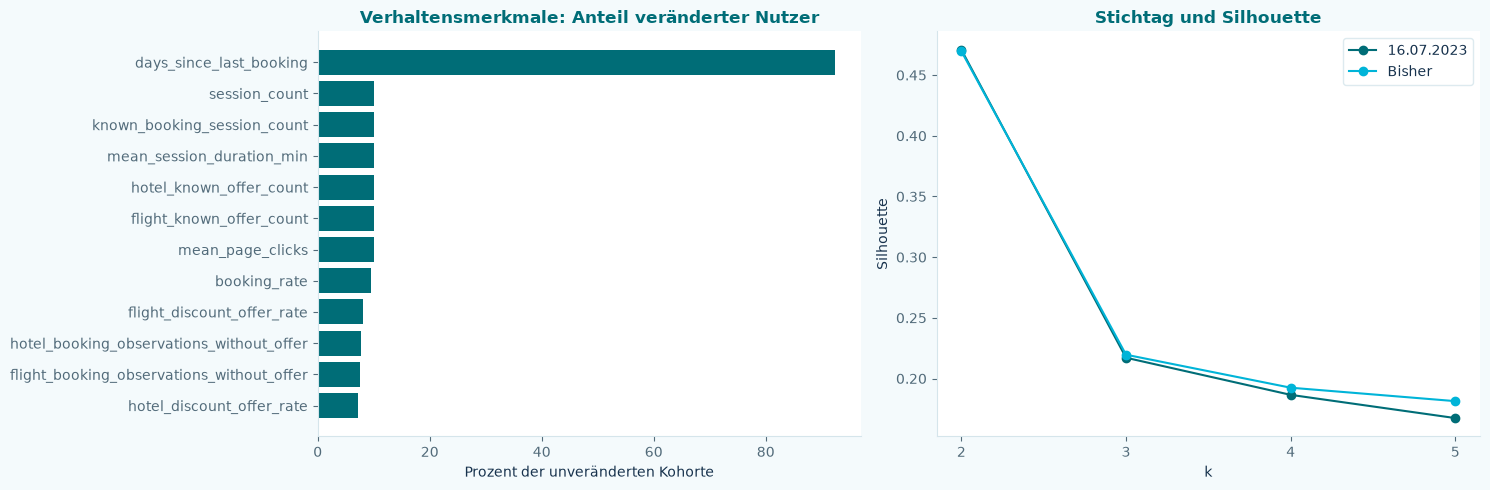

Aus dem Beobachtungsfenster entfernt: 624 Sessions von 604 Nutzern.
Baseline-Modell und Skalierung fest: {'Vergleich': 'Baseline-Modell und Skalierung fest', 'ARI': 0.9725056319295333, 'Geänderte Nutzer': 49}
Entscheidungsänderungen:
               Ergebnis  Geänderte Nutzer  Geändert (%)
                   rule               116      1.933978
baseline_recommendation                88      1.467156
       recommended_perk                10      0.166722
                 status               125      2.084028
            next_action               125      2.084028
Alter und Kundendauer ändern sich teilweise allein durch den früheren Referenztag; dies ist kein Verhaltenswechsel.
k=3 bleibt die konstante Arbeitslösung für den direkten Vergleich. Ein geänderter Silhouettewert allein entscheidet nicht über die finale Marketinglösung.


In [5]:
a=baseline["assignments"].reindex(before.index)
b=earlier["assignments"].reindex(before.index)
decision_changes=pd.DataFrame(index=before.index)
decision_changes["rule_before"]=baseline["rule_segments"]
decision_changes["rule_cutoff"]=earlier["rule_segments"]
for col in ["baseline_recommendation","recommended_perk","status","next_action"]:
    decision_changes[col+"_before"]=a[col]
    decision_changes[col+"_cutoff"]=b[col]
summary=[]
for col in ["rule","baseline_recommendation","recommended_perk","status","next_action"]:
    left=decision_changes[col+"_before"]
    right=decision_changes["rule_cutoff" if col=="rule" else col+"_cutoff"]
    changed=left.astype("string").fillna("<fehlend>").ne(right.astype("string").fillna("<fehlend>"))
    summary.append({"Ergebnis":col,"Geänderte Nutzer":int(changed.sum()),"Geändert (%)":changed.mean()*100})
decision_summary=pd.DataFrame(summary)
draw_table(decision_summary.round(3),"Änderungen bei Regeln und Perk-Vorschlägen")
draw_table(pd.crosstab(a.recommended_perk.fillna("Keine robuste Empfehlung"),b.recommended_perk.fillna("Keine robuste Empfehlung")),"Robuste Vorschläge: bisher → früherer Stichtag")
draw_table(pd.concat([a.status.value_counts().rename("Bisher"),b.status.value_counts().rename("16.07.")],axis=1).fillna(0).astype(int),"Evidenzstatus im Vergleich")
scope_summary=pd.DataFrame([
    {"Szenario":"Bisher","Stichtag":str(baseline["reference_date"]),"Nutzer":len(before),"Sessions":len(baseline["fs"]),"Gebuchte Reisen":int(before.booked_trip_count.sum()),"Robuste Vorschläge":int(a.recommended_perk.notna().sum())},
    {"Szenario":"16.07.2023","Stichtag":str(CUTOFF),"Nutzer":len(after),"Sessions":len(earlier["fs"]),"Gebuchte Reisen":int(after.booked_trip_count.sum()),"Robuste Vorschläge":int(b.recommended_perk.notna().sum())},
])
draw_table(scope_summary,"Beobachtungsumfang und Empfehlung im Vergleich")
fig,axes=plt.subplots(1,2,figsize=(15,5))
top=feature_changes.loc[~feature_changes.Feature.isin(["age_years","age_group","customer_tenure_days"])].head(12)
axes[0].barh(top.Feature.iloc[::-1],top["Geändert (%)"].iloc[::-1],color=THEME["primary"])
axes[0].set(title="Verhaltensmerkmale: Anteil veränderter Nutzer",xlabel="Prozent der unveränderten Kohorte")
for name,group in k_cutoff.groupby("Szenario"):
    axes[1].plot(group.k,group.Silhouette,marker="o",label=name)
axes[1].set(title="Stichtag und Silhouette",xlabel="k",ylabel="Silhouette");axes[1].set_xticks([2,3,4,5]);axes[1].legend()
fig.tight_layout();plt.show()

removed=baseline["fs"].loc[baseline["fs"].session_start.gt(CUTOFF)]
print(f"Aus dem Beobachtungsfenster entfernt: {len(removed):,} Sessions von {removed.user_id.nunique():,} Nutzern.")
print("Baseline-Modell und Skalierung fest:",cluster_comparison.iloc[0].to_dict())
print("Entscheidungsänderungen:");print(decision_summary.to_string(index=False))
print("Alter und Kundendauer ändern sich teilweise allein durch den früheren Referenztag; dies ist kein Verhaltenswechsel.")
print("k=3 bleibt die konstante Arbeitslösung für den direkten Vergleich. Ein geänderter Silhouettewert allein entscheidet nicht über die finale Marketinglösung.")

## 4. Getrennter Export und Grenzen
Die bisherigen Features und Empfehlungen bleiben erhalten. Ergebnisse werden ausschließlich
im neuen Vergleichsordner unter `config.DATA_FEATURES_FOLDER` gespeichert. Die
aufbewahrte Originalkohorte erlaubt einen direkten Vergleich pro Nutzer, beseitigt aber
nicht den ursprünglichen Selektionsbias. Eine alternative Kohortenauswahl wäre ein separater Test.

In [7]:
OUTPUT=config.DATA_FEATURES_FOLDER/"cutoff_comparison_20230716"
OUTPUT.mkdir(parents=True,exist_ok=True)
for name,frame in {"feature_changes":feature_changes,"cluster_comparison":cluster_comparison,"k_comparison":k_cutoff,"decision_summary":decision_summary,"scope_summary":scope_summary}.items():
    frame.to_csv(OUTPUT/f"{name}.csv",index=False)
for name,frame in {"user_features_before":before,"user_features_cutoff":after,"user_decision_changes":decision_changes,"user_decisions_cutoff":b}.items():
    frame.to_csv(OUTPUT/f"{name}.csv",index=True)
pd.DataFrame({"cluster_before":old_labels,"cluster_cutoff_fixed":fixed_labels,"cluster_cutoff_refit_aligned":aligned_refit}).to_csv(OUTPUT/"user_cluster_changes.csv")
assert source_hash==hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest()
assert input_hashes=={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in input_folder.glob("*.csv")}
metadata={"source_notebook":SOURCE_NOTEBOOK.name,"source_sha256":source_hash,"input_sha256":input_hashes,"cutoff":str(CUTOFF),"fixed_cohort":True,"users":len(before),"comparison_k":3,"limitation":"Keine historischen Versionen von Preisen/Stammdaten; Vergleich verwendet denselben aktuellen CSV-Stand."}
(OUTPUT/"comparison_metadata.json").write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding="utf8")
print(f"Vergleich gespeichert: {OUTPUT}. Quellen und ursprüngliche Feature-Ausgaben nicht überschrieben.")

Vergleich gespeichert: C:\Users\mwern\Documents\Codex\2026-10-15\session-start-date-session-start-2023\outputs\cutoff_results\cutoff_comparison_20230716. Quellen und ursprüngliche Feature-Ausgaben nicht überschrieben.


# Stichtagsvergleich: 16.07.2023 gegenüber bisherigem Datenende

Identische Kohorte: 5.998 Nutzer. Es wurden keine Nutzer neu ausgewählt.

| Ergebnis | Bisher | 16.07.2023, Tagesende UTC |
|---|---:|---:|
| Sessions | 49.211 | 48.587 |
| Beobachtete gebuchte Reisen | 16.099 | 15.851 |
| Robuste Perk-Arbeitshypothesen | 179 | 171 |

624 Sessions von 604 Nutzern werden aus dem Beobachtungsfenster entfernt.
Bei festem k=3-Modell einschließlich fester Skalierung wechseln 49 Nutzer (0,82 %) den Cluster;
ARI = 0,9725. Beim Neufit wechseln nach Angleichung der Cluster-Nummern 70 Nutzer (1,17 %);
ARI = 0,9603. Regelgruppen ändern sich bei 116 Nutzern (1,93 %), Basisvorschläge bei 88 (1,47 %),
robuste Vorschläge bei 10 (0,17 %) und Status bzw. nächste Aktion bei 125 (2,08 %).
Die absolute Zahl robuster Vorschläge fällt um acht; Zuordnungswechsel zählen auch Gewinne/Verluste.

## Bewertung
Die bisherige Gruppierung bleibt weitgehend erhalten. Der Datenbruch am Ende erklärt keine
grundlegende Änderung der Segmentierungslogik in dieser Kohorte. Für die weitere Auswertung
ist der frühere Stichtag dennoch vorzuziehen, weil er den auffälligen Datenendbereich ausschließt.
k=3 bleibt eine plausible explorative Arbeitslösung; seine Silhouette verändert sich von
0,2196 auf 0,2171. k=2 bleibt der technische Silhouette-Sieger, aber mit einer sehr großen Gruppe.
Es wurden hier keine neuen Teilstichproben-Stabilitätstests durchgeführt; der Vergleich misst
gezielt die Stichtags-Sensitivität.

Alter, Kundendauer und Tage seit letzter Buchung verändern sich auch rein rechnerisch durch
den früheren Referenztag. Diese Veränderungen dürfen nicht mit neuem Verhalten verwechselt werden.
Ein fehlender robuster Perk-Vorschlag bedeutet keine nachgewiesene Ablehnung eines Vorteils.

## Wichtige Grenze
486 Nutzer haben bis zum 16.07. weniger als acht Sessions. Sie bleiben bewusst in der ursprünglichen
Kohorte, damit der Vergleich dieselben Nutzer umfasst. Dies ist keine vollständig auf den früheren
Stichtag neu bestimmte Kohorte. Eine Neuauswahl wäre ein gesonderter Vergleich; der ursprüngliche
Selektionsbias bleibt hier bestehen. Preise und Stammdaten sind zudem nicht historisch versioniert.

Die ursprünglichen Eingabedateien und Notebooks wurden nicht verändert. Die Vergleichsdateien
enthalten technische Metadaten und SHA-256-Prüfsummen für die Quellen.
